# DISEASE: Hypertension

### 1. Load

In [ ]:
import pandas as pd
import numpy as np
from clean_datasets import age_years_to_ranges
df_raw = pd.read_csv("C:/Users/User/Documents/diploma/data/datasets_original/Hypertension-risk-model-main.csv")

print(df_raw.shape)
df_raw.head()

(4240, 13)


,male,age,currentSmoker,cigsPerDay,BPMeds,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Risk
0,1,39,0,0.0,0.0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,0,0.0,0.0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1,20.0,0.0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,1,30.0,0.0,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,1,23.0,0.0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


### 2. Rename columns

In [16]:
df = pd.DataFrame(index=df_raw.index)

df["diabetes"] = df_raw["diabetes"].astype("Int8")

df["hypertension"] = df_raw["Risk"].astype("Int8")

df["sex_binary"] = df_raw["male"].astype("Int8")
df["sex"] = df["sex_binary"].map({
    1: "male", 
    0: "female"
    }).astype("string")

df["age"] = df_raw["age"].astype("Int64")
df["age_range"] = age_years_to_ranges(df_raw["age"])

df["bmi"] = df_raw["BMI"].astype("float")

df["smoker"] = df_raw["currentSmoker"].astype("Int8") 
df["cigs_per_day"] = df_raw["cigsPerDay"].astype("float") 

df["systolic_bp"] = df_raw["sysBP"].astype("float")
df["diastolic_bp"] = df_raw["diaBP"].astype("float")
df["high_bp"] = (
    (df["systolic_bp"] >= 130) |
    (df["diastolic_bp"] >= 80)
).astype("Int8")

df["heart_rate"] = df_raw["heartRate"].astype("float")
df["bp_meds"] = df_raw["BPMeds"].astype("Int64")

df["cholesterol"] = df_raw["totChol"].astype("float")
df["high_chol"] = (df["cholesterol"] > 200).where(df["cholesterol"].notna()).astype("Int8")

df["glucose"] = df_raw["glucose"].astype("float")

df.head()

,diabetes,hypertension,sex_binary,sex,age,age_range,bmi,smoker,cigs_per_day,systolic_bp,diastolic_bp,high_bp,heart_rate,bp_meds,cholesterol,high_chol,glucose
0,0,0,1,male,39,4,26.97,0,0.0,106.0,70.0,0,80.0,0,195.0,0,77.0
1,0,0,0,female,46,6,28.73,0,0.0,121.0,81.0,1,95.0,0,250.0,1,76.0
2,0,0,1,male,48,6,25.34,1,20.0,127.5,80.0,1,75.0,0,245.0,1,70.0
3,0,1,0,female,61,9,28.58,1,30.0,150.0,95.0,1,65.0,0,225.0,1,103.0
4,0,0,0,female,46,6,23.10,1,23.0,130.0,84.0,1,85.0,0,285.0,1,85.0


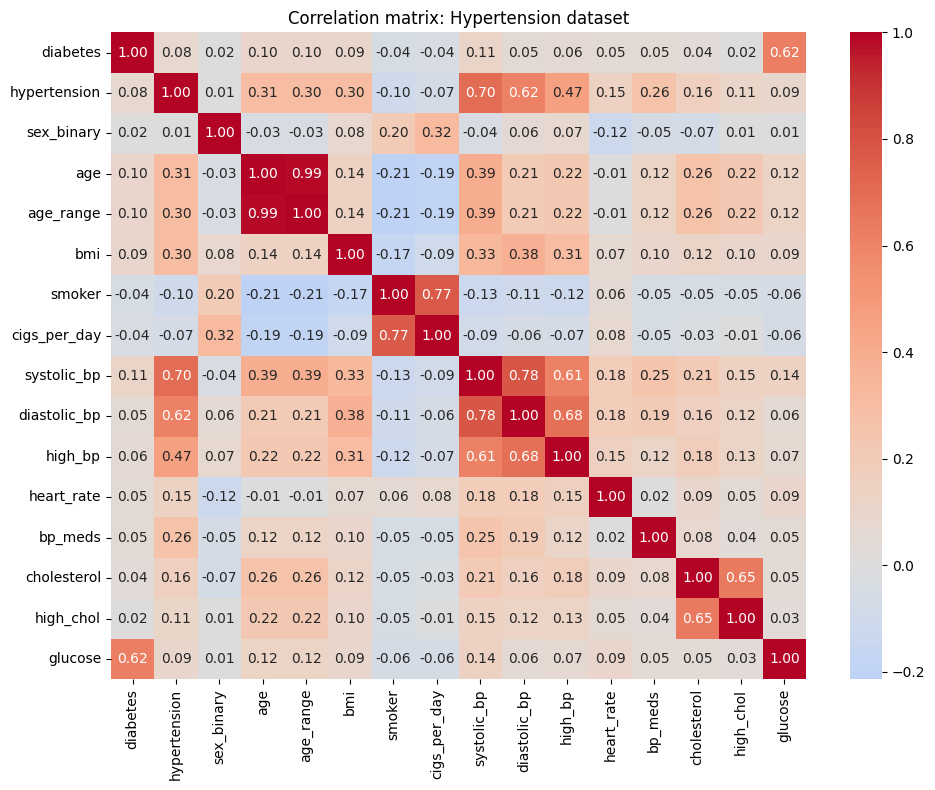

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix: Hypertension dataset")
plt.tight_layout()
plt.show()

In [11]:
target = "hypertension"
corr[target].drop(target).sort_values(key=abs, ascending=False)

systolic_bp     0.696656
diastolic_bp    0.615840
high_bp         0.467072
age             0.306799
age_range       0.301686
bmi             0.301344
bp_meds         0.261067
cholesterol     0.163632
heart_rate      0.146815
high_chol       0.106924
smoker         -0.103710
glucose         0.086656
diabetes        0.077752
cigs_per_day   -0.066645
sex_binary      0.005853
Name: hypertension, dtype: float64

### 3. Save cleaned dataset

In [ ]:
df.to_csv("C:/Users/User/Documents/diploma/data/datasets_cleaned/hypertension_clean.csv", index=False)

print(f"Saved {len(df)} rows × {df.shape[1]} columns")

Saved 4240 rows × 17 columns
